# Classifier for fish Calls


In [19]:
import torch
from torchvision import datasets, transforms, models
from torch.utils.data import DataLoader
import torch.optim as optim
import torch.nn as nn
from torch.utils.data import random_split
import torch.nn.functional as F
import random

import matplotlib.pyplot as plt

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

### Loading the Fake Data

In [20]:
transform = transforms.Compose([
    transforms.Grayscale(num_output_channels=1), #ensures 1-channel
    transforms.ToTensor(), # changes pixels and shape
    transforms.Normalize(mean=[0.5], std=[0.5])
])

bad_dataset = datasets.ImageFolder(
    root="D:/POTENTIAL Fish sounds/random_snips",
    transform=transform
)

loader_bad = DataLoader(bad_dataset, batch_size=32, shuffle=True) #Bigger is better - probably?

class UnlabeledWrapper(torch.utils.data.Dataset):
    def __init__(self, dataset):
        self.dataset = dataset

    def __len__(self):
        return len(self.dataset)

    def __getitem__(self, idx):
        x, _ = self.dataset[idx]   # ignore ImageFolder's random label
        return x, -1               # -1 = unlabeled


unlabeled_dataset = UnlabeledWrapper(bad_dataset)


In [21]:
print(bad_dataset.class_to_idx)

{'a': 0, 'b': 1, 'c': 2, 'd': 3, 'e': 4}


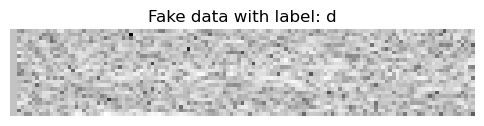

In [22]:
imgs, labels = next(iter(loader_bad))

img = imgs[0]
label_indx = labels[0].item()
img_np = img.squeeze().numpy()

plt.figure(figsize=(6,4))
plt.imshow(img_np, cmap='gray')
plt.title(f"Fake data with label: {bad_dataset.classes[label_indx]}")
plt.axis('off')
plt.show()

### Loading the Good Data: 

In [23]:
good_dataset = datasets.ImageFolder(
    root="D:/POTENTIAL Fish sounds/cnn_snips",
    transform=transform
)


train_size = int(0.8 * len(good_dataset))
val_size = len(good_dataset) - train_size

train_dataset, val_dataset = random_split(good_dataset, [train_size, val_size])

train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=32, shuffle=False)

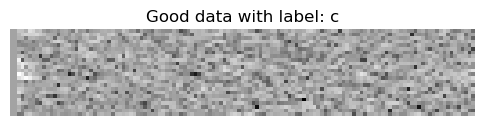

In [24]:
imgs, labels = next(iter(train_loader))

img = imgs[0]
label_indx = labels[0].item()
img_np = img.squeeze().numpy()

plt.figure(figsize=(6,4))
plt.imshow(img_np, cmap='gray')
plt.title(f"Good data with label: {good_dataset.classes[label_indx]}")
plt.axis('off')
plt.show()

In [25]:
from torch.utils.data import ConcatDataset

mixed_dataset = ConcatDataset([train_dataset, unlabeled_dataset])

mixed_loader = DataLoader(mixed_dataset, batch_size=32, shuffle=True)


### Initializing CNN

In [26]:
from torchvision.models import resnet18
import torch.nn as nn
import torch.nn.functional as F

class ResNet18Encoder(nn.Module):
    def __init__(self):
        super().__init__()
        base = resnet18(weights=None)
        base.conv1 = nn.Conv2d(1, 64, 3, stride=1, padding=1, bias=False)
        self.backbone = nn.Sequential(*list(base.children())[:-1])  # remove FC
        self.out_dim = 512

    def forward(self, x):
        h = self.backbone(x)      # [B, 512, 1, 1]
        return h.flatten(1)       # [B, 512]
class ProjectionHead(nn.Module):
    def __init__(self, in_dim=512, proj_dim=128):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(in_dim, 256),
            nn.ReLU(),
            nn.Linear(256, proj_dim)
        )

    def forward(self, x):
        return F.normalize(self.net(x), dim=1)
def supcon_loss(z, y, temperature=0.07):
    # z: [B, D], y: [B]
    device = z.device
    B = z.size(0)
    z = F.normalize(z, dim=1)

    sim = torch.matmul(z, z.T) / temperature
    mask = torch.eye(B, device=device).bool()
    sim = sim.masked_fill(mask, -9e15)

    labels = y.contiguous().view(-1, 1)
    matches = (labels == labels.T).float()
    matches = matches.masked_fill(mask, 0)

    log_prob = sim - torch.logsumexp(sim, dim=1, keepdim=True)
    numerator = (matches * log_prob).sum(dim=1)
    denom = matches.sum(dim=1).clamp(min=1e-6)
    loss = -(numerator / denom).mean()
    return loss
def augment_spectrogram(x):
    if random.random() < 0.5:
        t = random.randint(5, 20)
        t0 = random.randint(0, x.shape[-1] - t)
        x[:, :, :, t0:t0+t] = 0

    if random.random() < 0.5:
        f = random.randint(3, 8)
        f0 = random.randint(0, x.shape[-2] - f)
        x[:, :, f0:f0+f, :] = 0

    if random.random() < 0.5:
        x = x + 0.02 * torch.randn_like(x)

    return x


### Perform Pretraining

In [27]:
class SupConModel(nn.Module):
    def __init__(self):
        super().__init__()
        self.encoder = ResNet18Encoder()
        self.projector = ProjectionHead(self.encoder.out_dim, 128)

    def forward(self, x):
        h = self.encoder(x)
        z = self.projector(h)
        return z
def pretrain_supcon(model, loader, optimizer, epochs=50):
    model.train()
    for epoch in range(epochs):
        total_loss = 0
        for imgs, labels in loader:   # labels may be dummy for unlabeled; ignore or set -1
            imgs = imgs.to(device)
            labels = labels.to(device)

            # two views
            x1 = augment_spectrogram(imgs.clone())
            x2 = augment_spectrogram(imgs.clone())

            z1 = model(x1)
            z2 = model(x2)

            z = torch.cat([z1, z2], dim=0)
            y = torch.cat([labels, labels], dim=0)

            # keep only labeled samples in loss
            mask = (y != -1)
            z_l = z[mask]
            y_l = y[mask]

            if z_l.size(0) < 2:
                continue

            loss = supcon_loss(z_l, y_l)

            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

            total_loss += loss.item()

        print(f"Epoch {epoch+1}/{epochs}  SupCon Loss: {total_loss/len(loader):.4f}")
supcon_model = SupConModel().to(device)
optimizer = torch.optim.Adam(supcon_model.parameters(), lr=1e-3)
pretrain_supcon(supcon_model, mixed_loader, optimizer, epochs=50)

torch.save(supcon_model.encoder.state_dict(), "supcon_resnet18_encoder.pth")


Epoch 1/50  SupCon Loss: 0.3220
Epoch 2/50  SupCon Loss: 0.2948
Epoch 3/50  SupCon Loss: 0.3048
Epoch 4/50  SupCon Loss: 0.3332
Epoch 5/50  SupCon Loss: 0.2928
Epoch 6/50  SupCon Loss: 0.2683
Epoch 7/50  SupCon Loss: 0.2508
Epoch 8/50  SupCon Loss: 0.3010
Epoch 9/50  SupCon Loss: 0.2963
Epoch 10/50  SupCon Loss: 0.2578
Epoch 11/50  SupCon Loss: 0.2652
Epoch 12/50  SupCon Loss: 0.3357
Epoch 13/50  SupCon Loss: 0.2810
Epoch 14/50  SupCon Loss: 0.2688
Epoch 15/50  SupCon Loss: 0.2891
Epoch 16/50  SupCon Loss: 0.3080
Epoch 17/50  SupCon Loss: 0.2832
Epoch 18/50  SupCon Loss: 0.2616
Epoch 19/50  SupCon Loss: 0.2774
Epoch 20/50  SupCon Loss: 0.2779
Epoch 21/50  SupCon Loss: 0.2605
Epoch 22/50  SupCon Loss: 0.2664
Epoch 23/50  SupCon Loss: 0.2846
Epoch 24/50  SupCon Loss: 0.2603
Epoch 25/50  SupCon Loss: 0.2394
Epoch 26/50  SupCon Loss: 0.2702
Epoch 27/50  SupCon Loss: 0.2604
Epoch 28/50  SupCon Loss: 0.2591
Epoch 29/50  SupCon Loss: 0.2571
Epoch 30/50  SupCon Loss: 0.2447
Epoch 31/50  SupCon

### Actual Training: 

In [29]:
def fit(model, train_loader, optimizer, criterion, epochs, val_loader=None, scheduler=None):
    model.train()

    for epoch in range(epochs):
        total_loss = 0
        total_correct = 0
        total_samples = 0

        # -------------------------
        # Training loop
        # -------------------------
        for imgs, labels in train_loader:
            imgs = imgs.to(device)
            labels = labels.to(device)

            optimizer.zero_grad()
            outputs = model(imgs)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()

            total_loss += loss.item() * imgs.size(0)
            total_correct += (outputs.argmax(1) == labels).sum().item()
            total_samples += imgs.size(0)

        train_loss = total_loss / total_samples
        train_acc = total_correct / total_samples

        # -------------------------
        # Validation loop
        # -------------------------
        if val_loader is not None:
            model.eval()
            val_loss = 0
            val_correct = 0
            val_samples = 0

            with torch.no_grad():
                for imgs, labels in val_loader:
                    imgs = imgs.to(device)
                    labels = labels.to(device)

                    outputs = model(imgs)
                    loss = criterion(outputs, labels)

                    val_loss += loss.item() * imgs.size(0)
                    val_correct += (outputs.argmax(1) == labels).sum().item()
                    val_samples += imgs.size(0)

            val_loss /= val_samples
            val_acc = val_correct / val_samples
            model.train()

            print(f"Epoch {epoch+1}/{epochs}  "
                  f"Train Loss: {train_loss:.4f}  Train Acc: {train_acc:.4f}  "
                  f"Val Loss: {val_loss:.4f}  Val Acc: {val_acc:.4f}")

        else:
            print(f"Epoch {epoch+1}/{epochs}  Train Loss: {train_loss:.4f}  Train Acc: {train_acc:.4f}")

        # -------------------------
        # Scheduler step
        # -------------------------
        if scheduler is not None:
            scheduler.step()


In [30]:
finetune_model = resnet18(weights=None)
finetune_model.conv1 = nn.Conv2d(1, 64, 3, stride=1, padding=1, bias=False)

finetune_model.load_state_dict(torch.load("supcon_resnet18_encoder.pth"), strict=False)

finetune_model.fc = nn.Sequential(
    nn.Linear(512, 256),
    nn.ReLU(),
    nn.Dropout(0.3),
    nn.Linear(256, 5)
)

finetune_model = finetune_model.to(device)

criterion = nn.CrossEntropyLoss(label_smoothing=0.1)
optimizer = torch.optim.Adam([
    {"params": finetune_model.conv1.parameters(), "lr": 1e-5},
    {"params": finetune_model.layer1.parameters(), "lr": 1e-5},
    {"params": finetune_model.layer2.parameters(), "lr": 1e-5},
    {"params": finetune_model.layer3.parameters(), "lr": 1e-5},
    {"params": finetune_model.layer4.parameters(), "lr": 1e-5},
    {"params": finetune_model.fc.parameters(), "lr": 1e-3},
])

scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
    optimizer, T_max=50, eta_min=1e-6
)

fit(
    finetune_model,
    train_loader,
    optimizer,
    criterion,
    epochs=100,
    val_loader=val_loader,
    scheduler=scheduler
)


C:\Users\Felic\AppData\Local\Temp\ipykernel_38828\1935122767.py:4: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  finetune_model.load_state_dict(torch.load("supcon_resnet18_e

Epoch 1/100  Train Loss: 1.3385  Train Acc: 0.4115  Val Loss: 1.2877  Val Acc: 0.3958
Epoch 2/100  Train Loss: 1.2898  Train Acc: 0.4479  Val Loss: 1.2356  Val Acc: 0.4167
Epoch 3/100  Train Loss: 1.2119  Train Acc: 0.4635  Val Loss: 1.2321  Val Acc: 0.4792
Epoch 4/100  Train Loss: 1.1691  Train Acc: 0.5521  Val Loss: 1.2498  Val Acc: 0.3958
Epoch 5/100  Train Loss: 1.1416  Train Acc: 0.5260  Val Loss: 1.2326  Val Acc: 0.4792
Epoch 6/100  Train Loss: 1.1198  Train Acc: 0.5573  Val Loss: 1.2394  Val Acc: 0.4375
Epoch 7/100  Train Loss: 1.0993  Train Acc: 0.6146  Val Loss: 1.2466  Val Acc: 0.4792
Epoch 8/100  Train Loss: 1.0306  Train Acc: 0.6406  Val Loss: 1.2476  Val Acc: 0.4167
Epoch 9/100  Train Loss: 0.8972  Train Acc: 0.7656  Val Loss: 1.2639  Val Acc: 0.4792
Epoch 10/100  Train Loss: 0.8208  Train Acc: 0.7760  Val Loss: 1.2433  Val Acc: 0.5417
Epoch 11/100  Train Loss: 0.7141  Train Acc: 0.8646  Val Loss: 1.3293  Val Acc: 0.3958
Epoch 12/100  Train Loss: 0.6791  Train Acc: 0.8594 

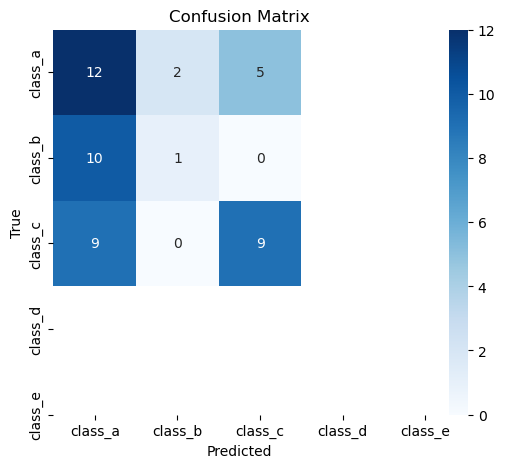

In [31]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

def get_predictions(model, loader):
    model.eval()
    all_preds, all_labels = [], []
    with torch.no_grad():
        for imgs, labels in loader:
            imgs = imgs.to(device)
            labels = labels.to(device)
            outputs = model(imgs)
            preds = outputs.argmax(dim=1)
            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())
    return np.array(all_labels), np.array(all_preds)

y_true, y_pred = get_predictions(finetune_model, val_loader)
cm = confusion_matrix(y_true, y_pred)
class_names = ["class_a", "class_b", "class_c", "class_d", "class_e"]  # your labels

plt.figure(figsize=(6,5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=class_names,
            yticklabels=class_names)
plt.xlabel("Predicted")
plt.ylabel("True")
plt.title("Confusion Matrix")
plt.show()
